GROUP A — Static / Point-in-Time Bond Characteristics
  Characteristics : #1 bond_age  #2 coupon  #3 face_value
                    #6 duration  #18 spread  #22 rating
  Shape           : 97,893 rows × 8 columns
  Unique RICs     : 1,699
  Date range      : 2004-07-31  →  2025-09-30

── Summary statistics ──────────────────────────────────
            NaN count  NaN %      Mean      Std      Min   Median       Max
bond_age            0    0.0     4.144    3.738   -0.049    3.162    29.919
coupon              0    0.0     4.132    1.337    0.750    4.100     8.875
face_value          0    0.0  1118.078  733.426  502.000  900.000  8000.000
duration            0    0.0     9.492    4.916    0.035    8.280    25.401
spread              0    0.0   125.160   70.909 -426.372  119.162  1498.475
rating              0    0.0     7.259    2.056    1.000    8.000    11.000

── Data quirks ─────────────────────────────────────────
  Negative bond_age rows  : 1  (issue_date > month_end by rounding)


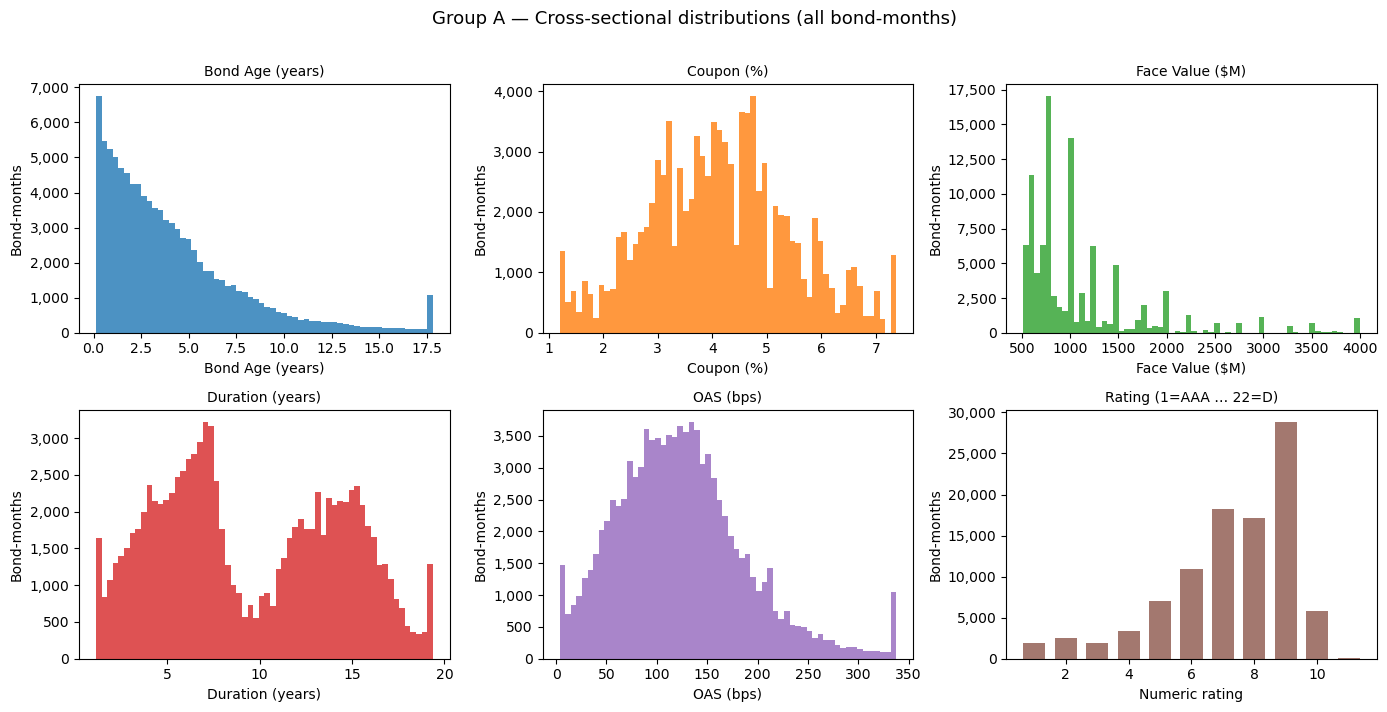

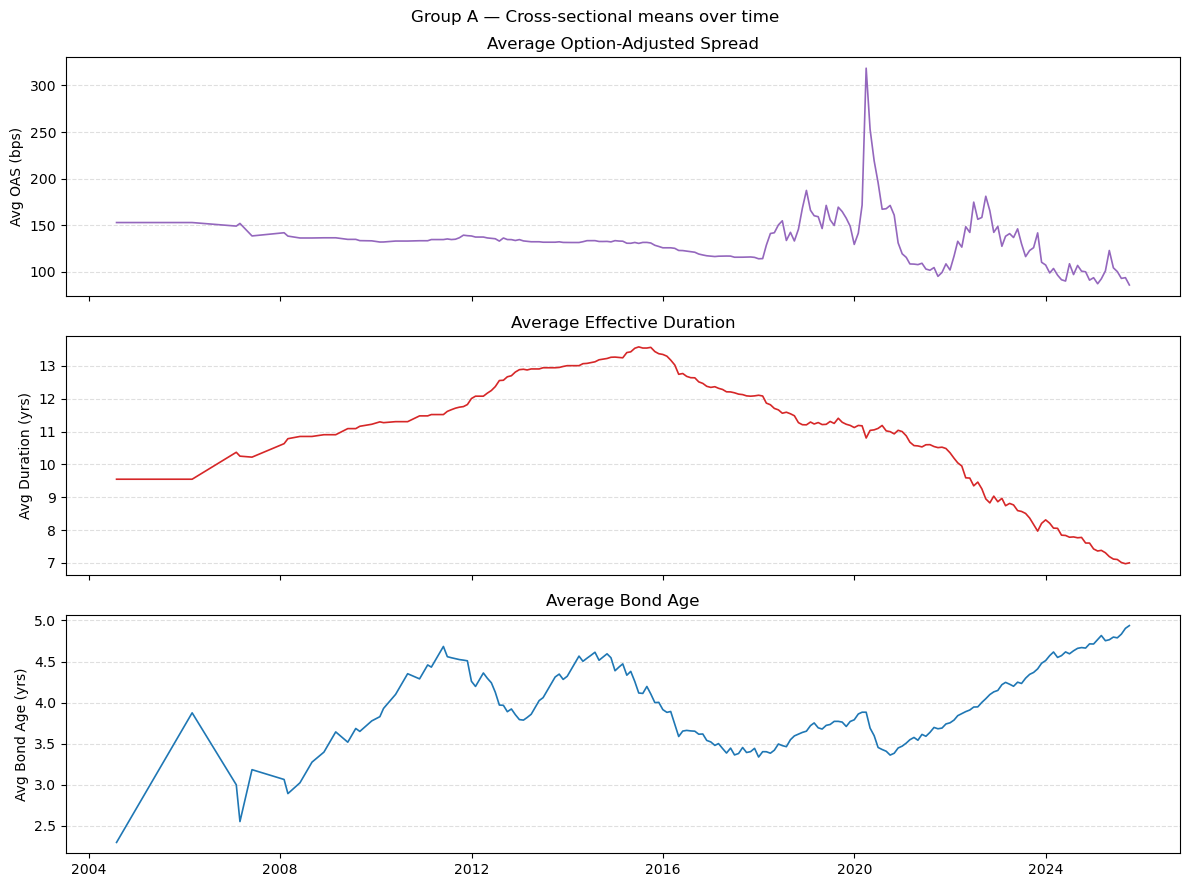

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── Load ──────────────────────────────────────────────────────────────────────
out = pd.read_parquet("outputs/characteristics_group_a.parquet")
out = out.reset_index()

print("=" * 60)
print("GROUP A — Static / Point-in-Time Bond Characteristics")
print("=" * 60)
print(f"  Characteristics : #1 bond_age  #2 coupon  #3 face_value")
print(f"                    #6 duration  #18 spread  #22 rating")
print(f"  Shape           : {out.shape[0]:,} rows × {out.shape[1]} columns")
print(f"  Unique RICs     : {out['RIC'].nunique():,}")
print(f"  Date range      : {out['month_end'].min().date()}  →  {out['month_end'].max().date()}")
print()

# ── Coverage ──────────────────────────────────────────────────────────────────
char_cols = ["bond_age", "coupon", "face_value", "duration", "spread", "rating"]
coverage = pd.DataFrame({
    "NaN count": out[char_cols].isna().sum(),
    "NaN %":     (out[char_cols].isna().mean() * 100).round(2),
    "Mean":      out[char_cols].mean().round(3),
    "Std":       out[char_cols].std().round(3),
    "Min":       out[char_cols].min().round(3),
    "Median":    out[char_cols].median().round(3),
    "Max":       out[char_cols].max().round(3),
})
print("── Summary statistics ──────────────────────────────────")
print(coverage.to_string())
print()

# ── Flag quirks ───────────────────────────────────────────────────────────────
n_neg_age    = (out["bond_age"] < 0).sum()
n_neg_spread = (out["spread"] < 0).sum()
max_rating   = out["rating"].max()

print("── Data quirks ─────────────────────────────────────────")
print(f"  Negative bond_age rows  : {n_neg_age}  (issue_date > month_end by rounding)")
print(f"  Negative spread rows    : {n_neg_spread}  (OAS < 0, real phenomenon — keep)")
print(f"  Max rating value        : {max_rating:.0f}  (paper scale 1=AAA … 22=D; "
      f"{'IG-only universe ✓' if max_rating <= 11 else 'includes HY'})")
print()

# ── Plots ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
fig.suptitle("Group A — Cross-sectional distributions (all bond-months)", fontsize=13, y=1.01)

plot_cfg = [
    ("bond_age",   "Bond Age (years)",          "tab:blue"),
    ("coupon",     "Coupon (%)",                 "tab:orange"),
    ("face_value", "Face Value ($M)",            "tab:green"),
    ("duration",   "Duration (years)",           "tab:red"),
    ("spread",     "OAS (bps)",                  "tab:purple"),
    ("rating",     "Rating (1=AAA … 22=D)",      "tab:brown"),
]

for ax, (col, label, color) in zip(axes.flat, plot_cfg):
    vals = out[col].dropna()
    if col == "rating":
        # bar chart: count per rating bucket
        counts = vals.value_counts().sort_index()
        ax.bar(counts.index, counts.values, color=color, alpha=0.8, width=0.7)
        ax.set_xlabel("Numeric rating")
        ax.set_ylabel("Bond-months")
    else:
        p1, p99 = vals.quantile(0.01), vals.quantile(0.99)
        ax.hist(vals.clip(p1, p99), bins=60, color=color, alpha=0.8, edgecolor="none")
        ax.set_xlabel(label)
        ax.set_ylabel("Bond-months")
        ax.set_title(f"(clipped to p1–p99)")
    ax.set_title(f"{label}", fontsize=10)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.tight_layout()
plt.show()

# ── Time-series: average spread and duration by month ─────────────────────────
monthly = out.groupby("month_end")[["spread", "duration", "bond_age"]].mean()

fig2, axes2 = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
fig2.suptitle("Group A — Cross-sectional means over time", fontsize=12)

axes2[0].plot(monthly.index, monthly["spread"],   color="tab:purple", linewidth=1.2)
axes2[0].set_ylabel("Avg OAS (bps)")
axes2[0].set_title("Average Option-Adjusted Spread")

axes2[1].plot(monthly.index, monthly["duration"], color="tab:red",    linewidth=1.2)
axes2[1].set_ylabel("Avg Duration (yrs)")
axes2[1].set_title("Average Effective Duration")

axes2[2].plot(monthly.index, monthly["bond_age"], color="tab:blue",   linewidth=1.2)
axes2[2].set_ylabel("Avg Bond Age (yrs)")
axes2[2].set_title("Average Bond Age")

for ax in axes2:
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

GROUP B — Rolling Time-Series Bond Characteristics
  Characteristics : #12 mom_6m            #13 mom_6m_industry
                    #14 mom_6m_x_rating   #24 bond_skewness
                    #25 mom_6m_log_spread #27 bond_volatility
                    #28 value_at_risk
  Shape           : 97,893 rows × 9 columns
  Unique RICs     : 1,699
  Date range      : 2004-07-31  →  2025-09-30

── Summary statistics ──────────────────────────────────
                   NaN %    Mean     Std     p25  Median     p75                                         Note
mom_6m              11.8 -0.0083  0.0699 -0.0441 -0.0040  0.0302              6m window, min 6 obs (skip t-1)
mom_6m_industry     11.8  0.0000  0.0334 -0.0178  0.0007  0.0174                          derived from mom_6m
mom_6m_x_rating     11.8 -0.0570  0.5301 -0.2903 -0.0245  0.2042                 derived from mom_6m × rating
bond_skewness       71.1  0.0606  0.3107 -0.0862  0.0820  0.2415  60m window, min 24 obs  ← high NaN expected
mom

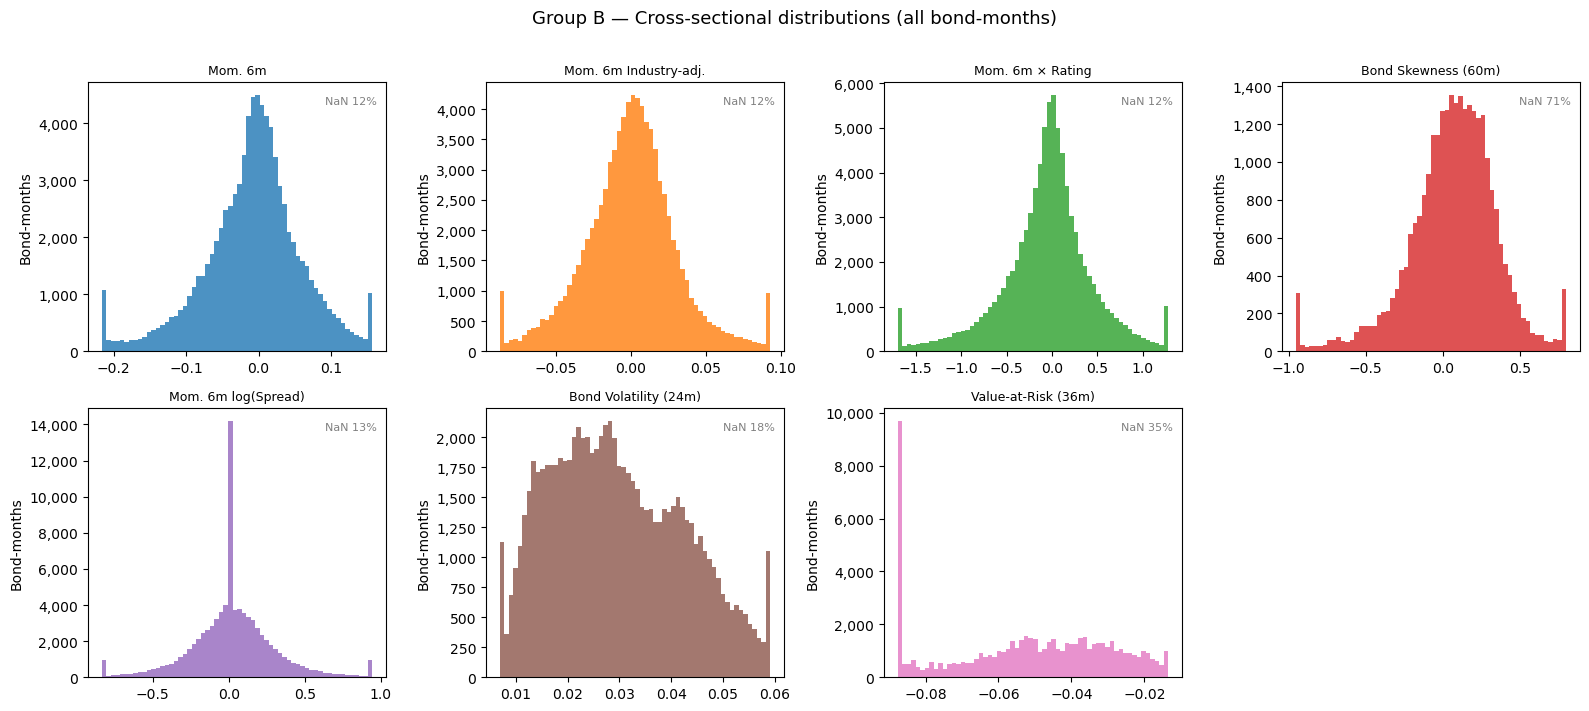

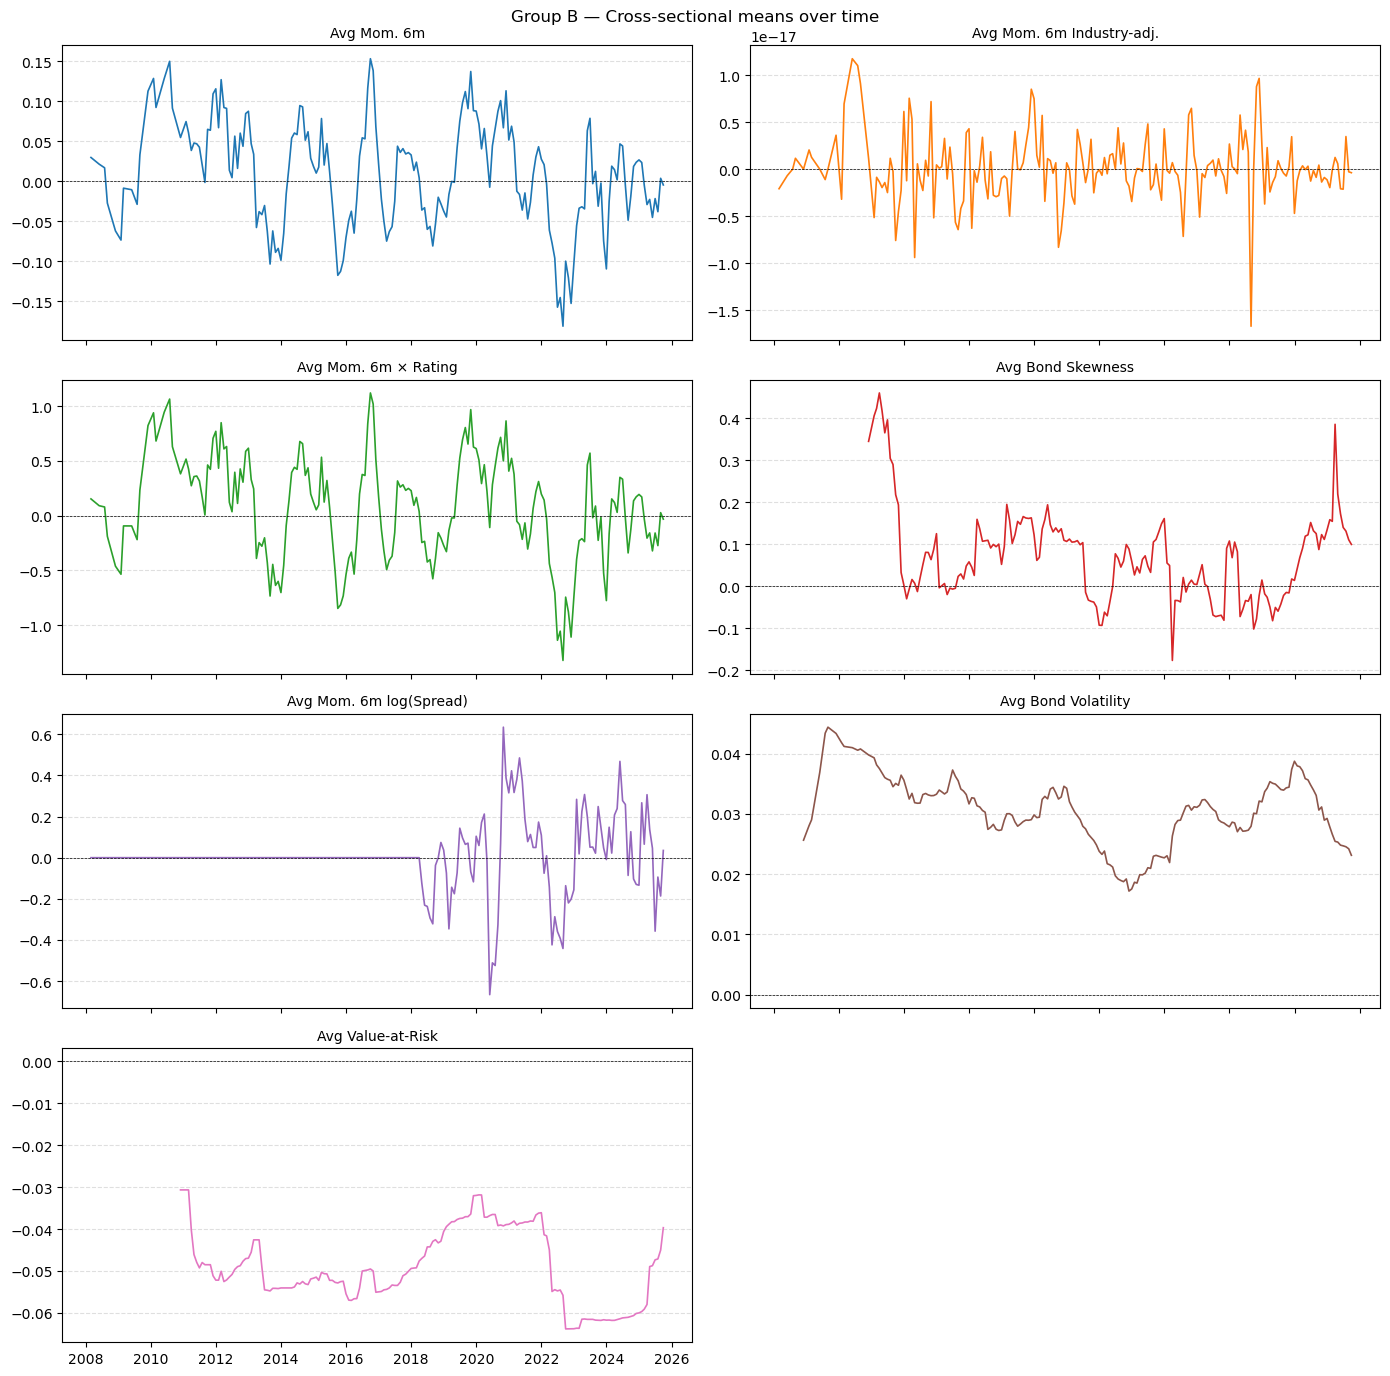

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── Load ──────────────────────────────────────────────────────────────────────
out = pd.read_parquet("outputs/characteristics_group_b.parquet")
out = out.reset_index()

print("=" * 60)
print("GROUP B — Rolling Time-Series Bond Characteristics")
print("=" * 60)
print(f"  Characteristics : #12 mom_6m            #13 mom_6m_industry")
print(f"                    #14 mom_6m_x_rating   #24 bond_skewness")
print(f"                    #25 mom_6m_log_spread #27 bond_volatility")
print(f"                    #28 value_at_risk")
print(f"  Shape           : {out.shape[0]:,} rows × {out.shape[1]} columns")
print(f"  Unique RICs     : {out['RIC'].nunique():,}")
print(f"  Date range      : {out['month_end'].min().date()}  →  {out['month_end'].max().date()}")
print()

# ── Coverage ──────────────────────────────────────────────────────────────────
char_cols = [
    "mom_6m", "mom_6m_industry", "mom_6m_x_rating",
    "bond_skewness", "mom_6m_log_spread", "bond_volatility", "value_at_risk",
]

window_note = {
    "mom_6m":             "6m window, min 6 obs (skip t-1)",
    "mom_6m_industry":    "derived from mom_6m",
    "mom_6m_x_rating":    "derived from mom_6m × rating",
    "bond_skewness":      "60m window, min 24 obs  ← high NaN expected",
    "mom_6m_log_spread":  "log(OAS_{t-7}) − log(OAS_{t-2})",
    "bond_volatility":    "24m window, min 12 obs",
    "value_at_risk":      "36m window, min 24 obs (2nd-lowest CER)",
}

coverage = pd.DataFrame({
    "NaN %":   (out[char_cols].isna().mean() * 100).round(1),
    "Mean":    out[char_cols].mean().round(4),
    "Std":     out[char_cols].std().round(4),
    "p25":     out[char_cols].quantile(0.25).round(4),
    "Median":  out[char_cols].median().round(4),
    "p75":     out[char_cols].quantile(0.75).round(4),
    "Note":    pd.Series(window_note),
})
print("── Summary statistics ──────────────────────────────────")
print(coverage.to_string())
print()

# ── Sanity checks ─────────────────────────────────────────────────────────────
print("── Sanity checks ───────────────────────────────────────")

# mom_6m_industry mean should be ~0 each month
monthly_ind_mean = out.groupby("month_end")["mom_6m_industry"].mean()
print(f"  mom_6m_industry cross-sectional mean ≈ 0 each month?")
print(f"    Mean of monthly means : {monthly_ind_mean.mean():.2e}  (should be ~0)")
print(f"    Std  of monthly means : {monthly_ind_mean.std():.2e}  (should be very small)")

# bond_volatility should be non-negative
n_neg_vol = (out["bond_volatility"] < 0).sum()
print(f"  Negative bond_volatility rows : {n_neg_vol}  (should be 0)")

# value_at_risk should be negative (2nd-lowest CER in IG universe)
pct_neg_var = (out["value_at_risk"] < 0).mean() * 100
print(f"  value_at_risk < 0 : {pct_neg_var:.1f}%  (expected ~100% for IG bonds)")

# mom_6m_log_spread: median ~0 means roughly half bonds had spread compression
pct_pos_lsp = (out["mom_6m_log_spread"] > 0).mean() * 100
print(f"  mom_6m_log_spread > 0 (spread fell) : {pct_pos_lsp:.1f}%")
print()

# ── Plots: cross-sectional distributions ─────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
fig.suptitle("Group B — Cross-sectional distributions (all bond-months)", fontsize=13, y=1.01)

plot_cfg = [
    ("mom_6m",             "Mom. 6m",                  "tab:blue"),
    ("mom_6m_industry",    "Mom. 6m Industry-adj.",     "tab:orange"),
    ("mom_6m_x_rating",    "Mom. 6m × Rating",          "tab:green"),
    ("bond_skewness",      "Bond Skewness (60m)",        "tab:red"),
    ("mom_6m_log_spread",  "Mom. 6m log(Spread)",        "tab:purple"),
    ("bond_volatility",    "Bond Volatility (24m)",      "tab:brown"),
    ("value_at_risk",      "Value-at-Risk (36m)",        "tab:pink"),
]

for ax, (col, label, color) in zip(axes.flat, plot_cfg):
    vals = out[col].dropna()
    p1, p99 = vals.quantile(0.01), vals.quantile(0.99)
    ax.hist(vals.clip(p1, p99), bins=60, color=color, alpha=0.8, edgecolor="none")
    ax.set_title(label, fontsize=9)
    ax.set_ylabel("Bond-months")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
    nan_pct = out[col].isna().mean() * 100
    ax.text(0.97, 0.95, f"NaN {nan_pct:.0f}%", transform=ax.transAxes,
            ha="right", va="top", fontsize=8, color="grey")

axes.flat[-1].set_visible(False)   # 8th panel unused
plt.tight_layout()
plt.show()

# ── Time-series: cross-sectional means by month ───────────────────────────────
monthly = out.groupby("month_end")[char_cols].mean()

fig2, axes2 = plt.subplots(4, 2, figsize=(14, 14), sharex=True)
fig2.suptitle("Group B — Cross-sectional means over time", fontsize=12)

ts_cfg = [
    ("mom_6m",             "Avg Mom. 6m",               "tab:blue"),
    ("mom_6m_industry",    "Avg Mom. 6m Industry-adj.", "tab:orange"),
    ("mom_6m_x_rating",    "Avg Mom. 6m × Rating",      "tab:green"),
    ("bond_skewness",      "Avg Bond Skewness",          "tab:red"),
    ("mom_6m_log_spread",  "Avg Mom. 6m log(Spread)",   "tab:purple"),
    ("bond_volatility",    "Avg Bond Volatility",        "tab:brown"),
    ("value_at_risk",      "Avg Value-at-Risk",          "tab:pink"),
]

for ax, (col, label, color) in zip(axes2.flat, ts_cfg):
    ax.plot(monthly.index, monthly[col], color=color, linewidth=1.2)
    ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
    ax.set_title(label, fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes2.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

GROUP C — Firm-Level Characteristics
  C1 Financials : #4 book_to_price    #5 debt_to_ebitda
                  #8 earnings_to_price #11 firm_total_debt
                  #15 book_leverage    #16 market_leverage
                  #17 turnover_vol     #19 operating_leverage
                  #20 profitability    #21 profitability_change
  C2 Market Cap : #9 equity_market_cap
  C3 Equity     : #7 mom_6m_equity     #10 equity_volatility
                  #23 distance_to_default
  Shape         : 97,893 rows × 16 columns
  Unique RICs   : 1,699
  Date range    : 2004-07-31  →  2025-09-30

── Summary statistics ──────────────────────────────────
                      NaN %          Mean           Std           p25        Median           p75                                             Note
book_to_price          10.5  3.347000e-01  3.562000e-01  7.180000e-02  2.112000e-01  5.177000e-01                                  needs marketCap
debt_to_ebitda         18.8  1.038444e+02  1.491202e+04  7

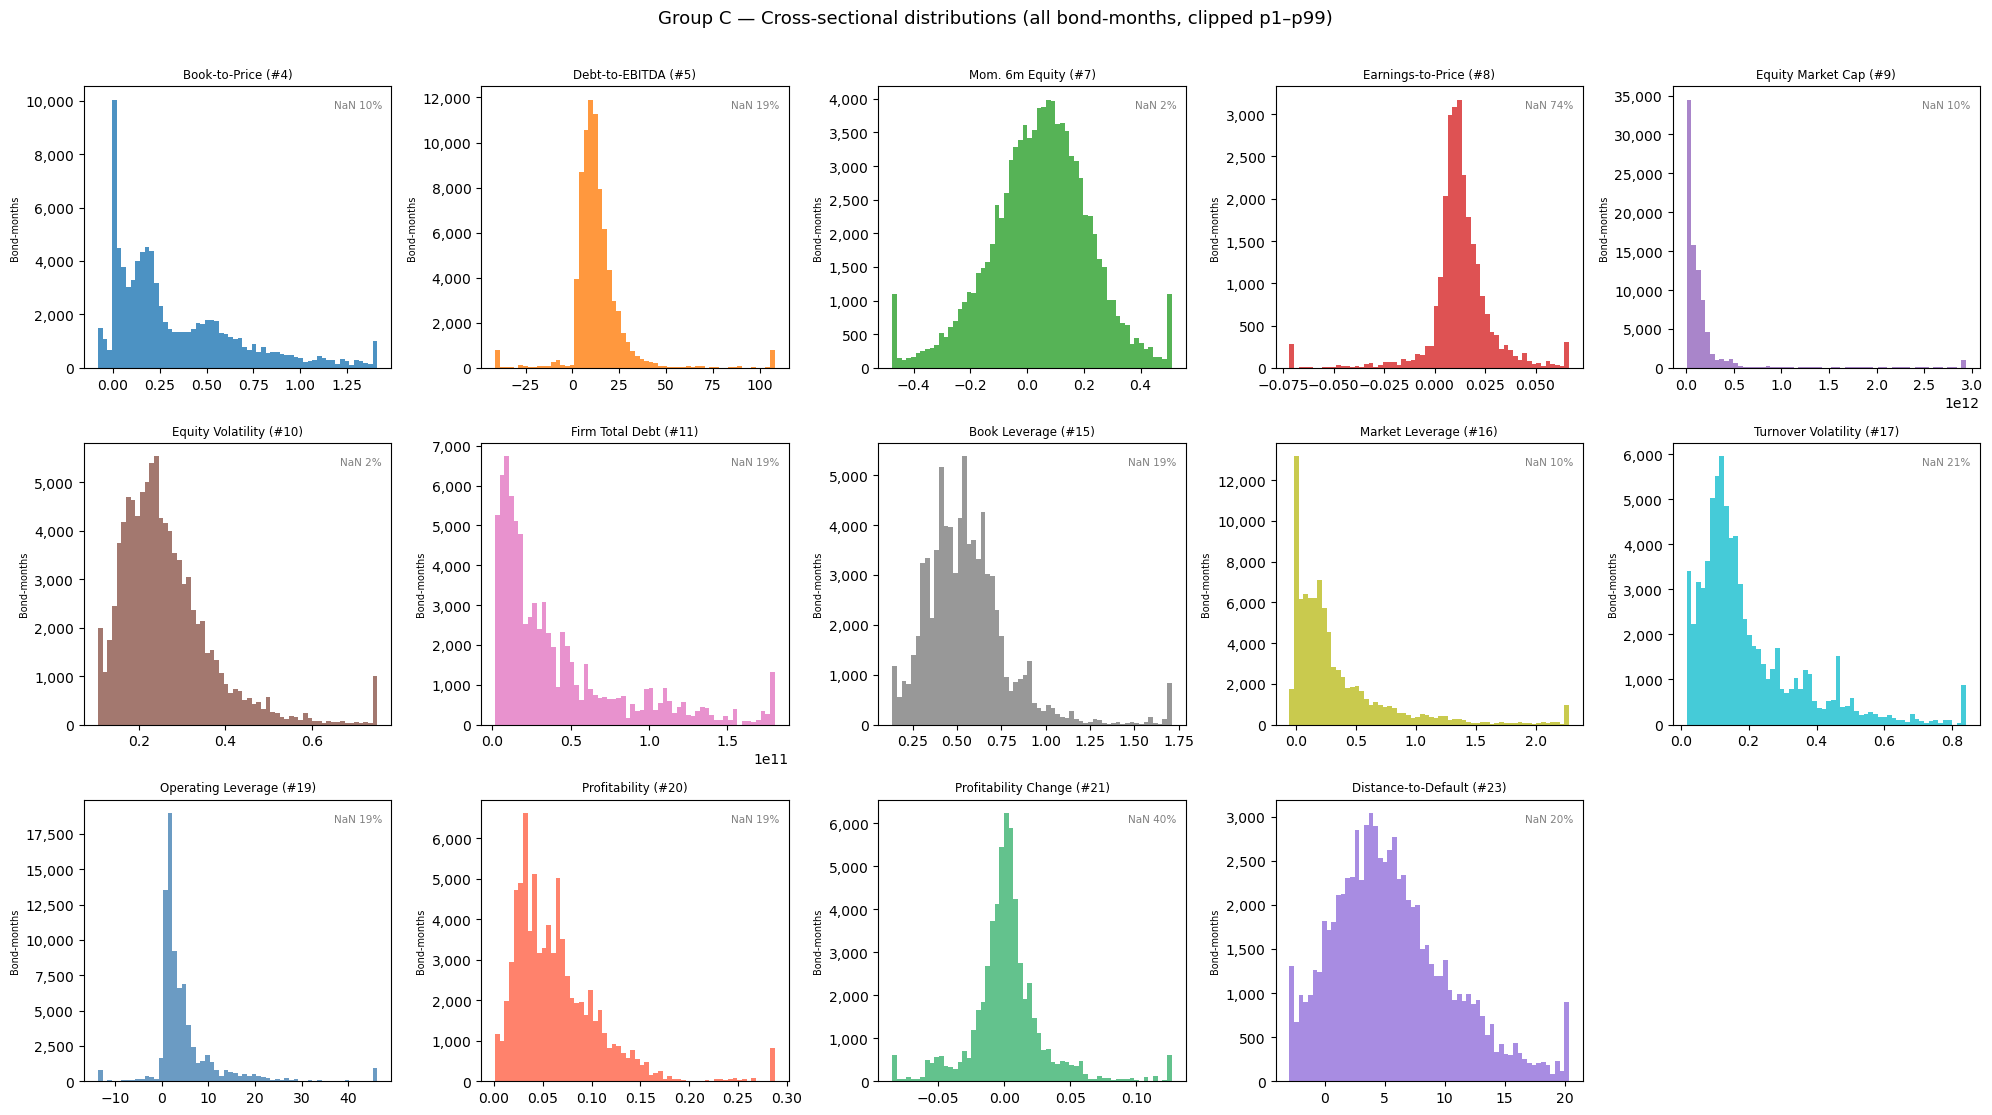

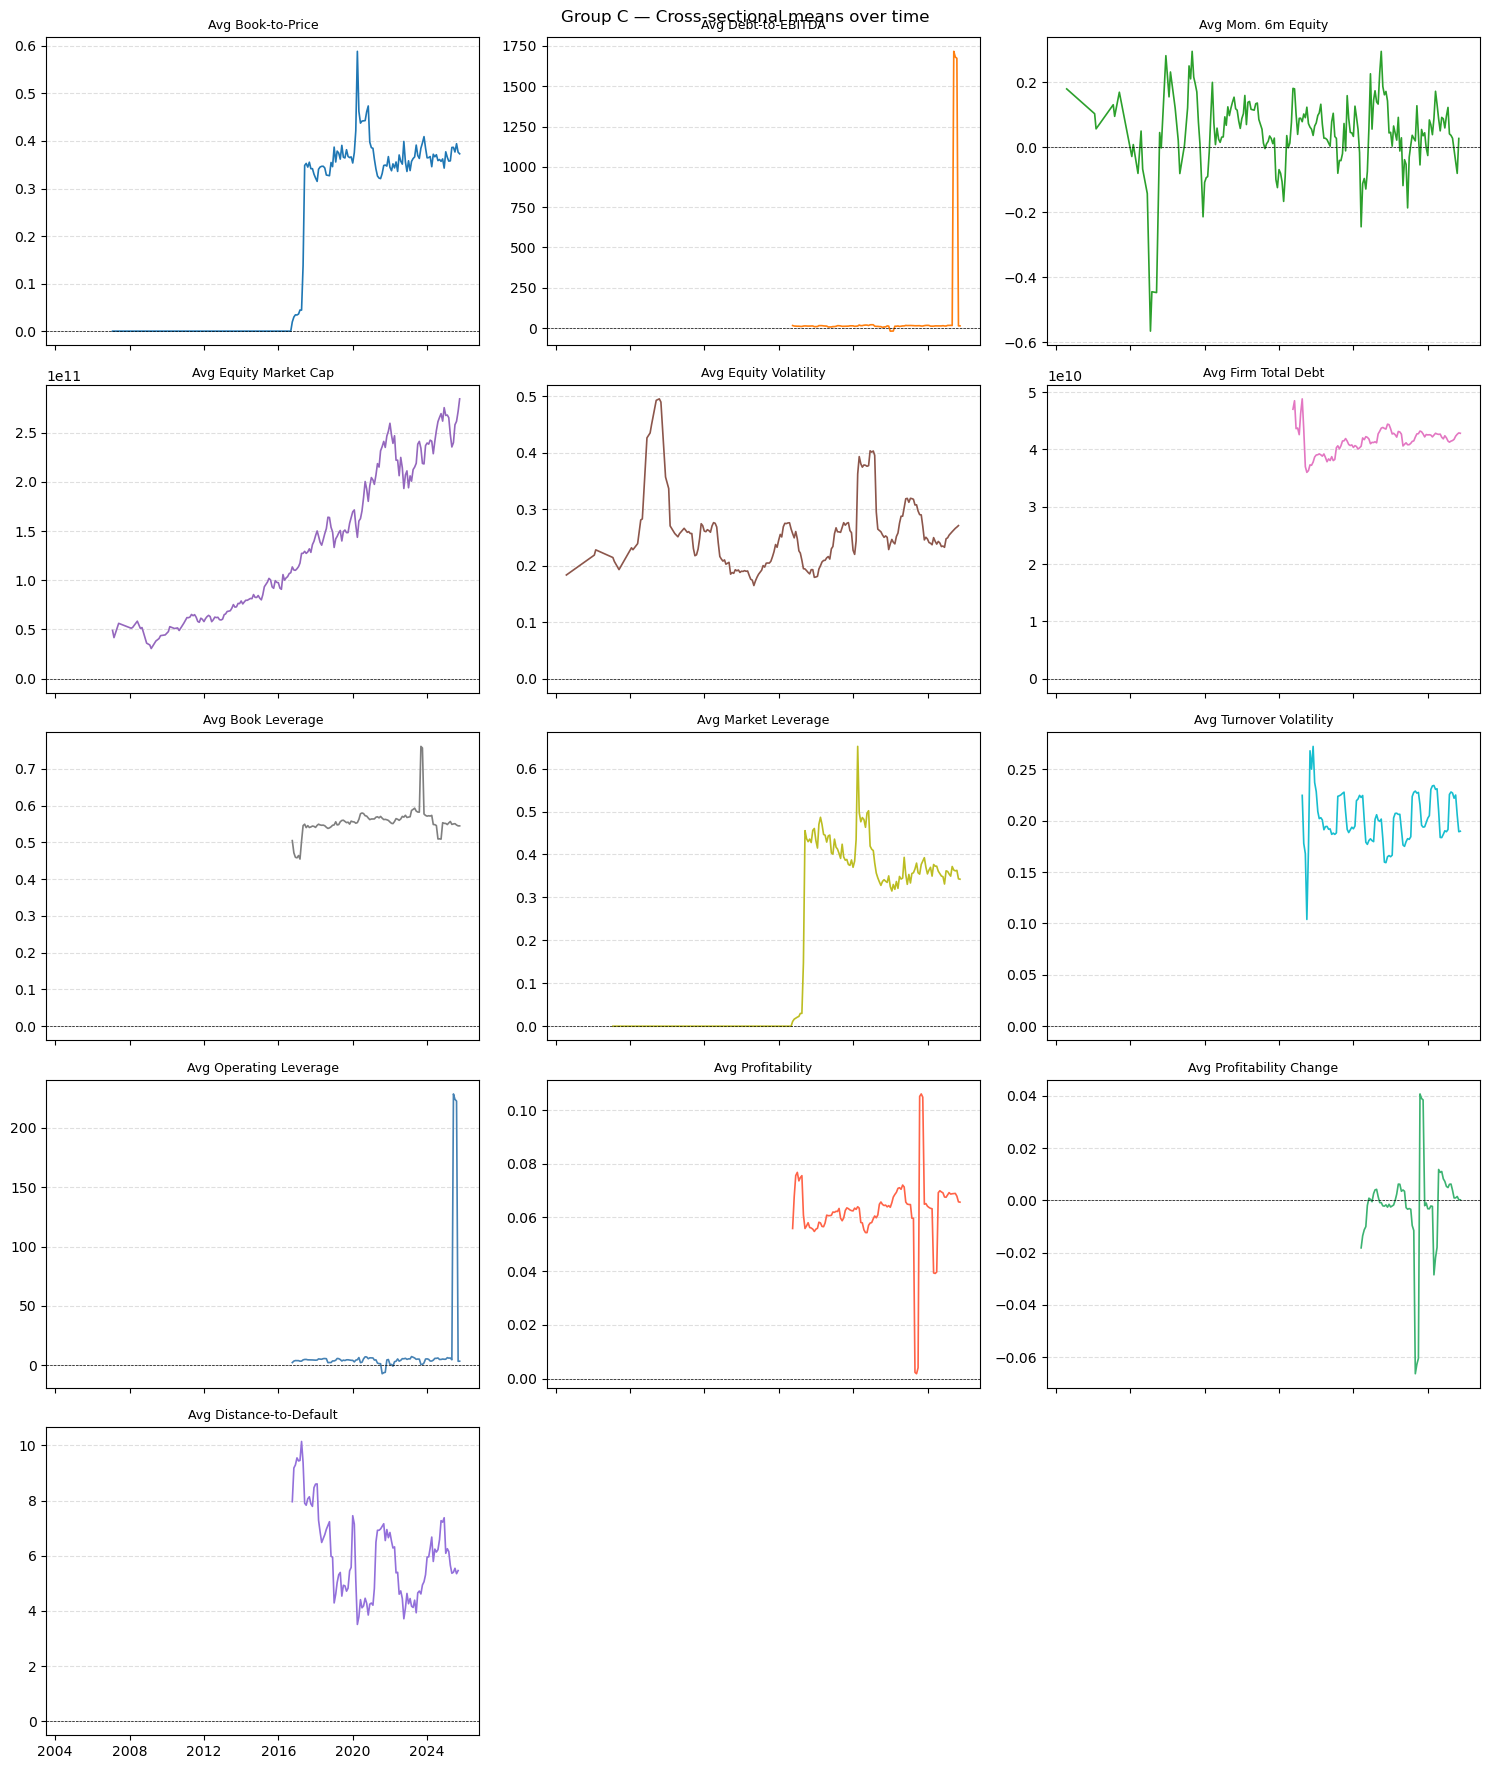

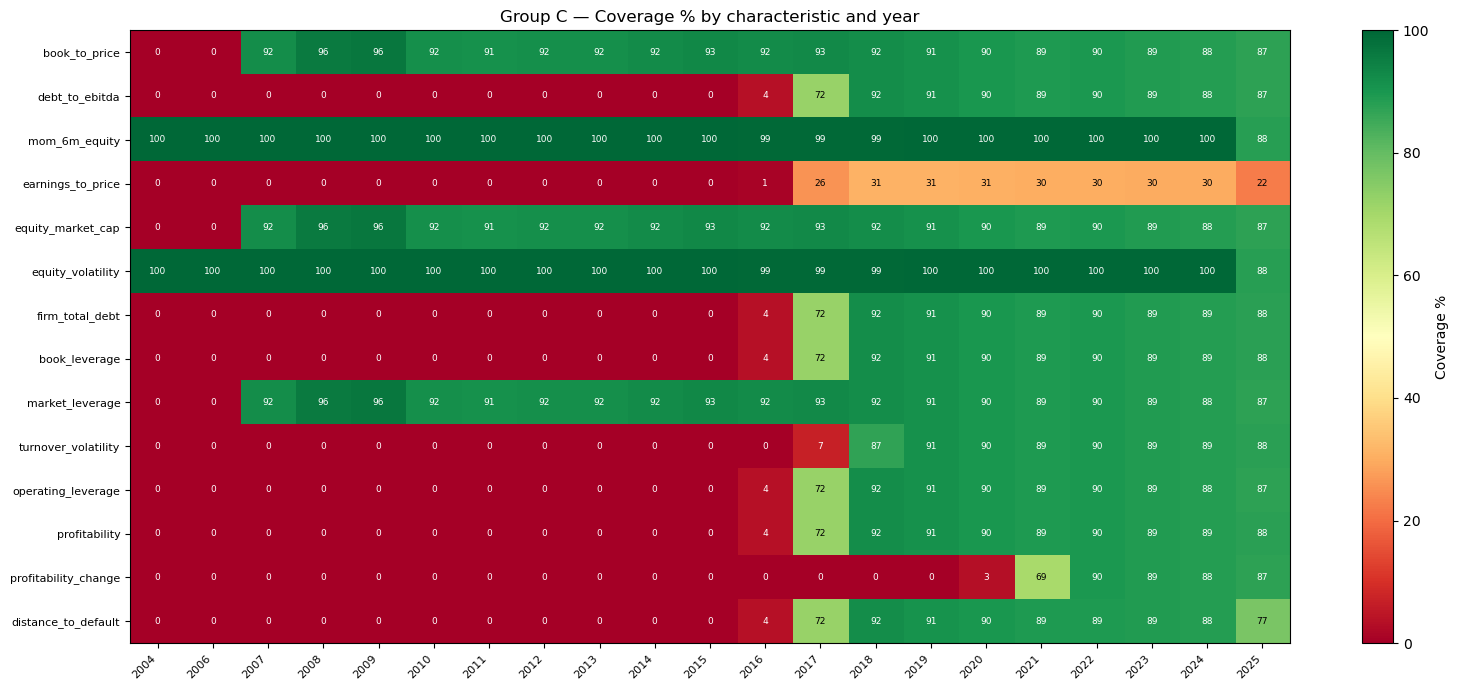

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── Load ──────────────────────────────────────────────────────────────────────
out = pd.read_parquet("outputs/characteristics_group_c.parquet")
out = out.reset_index()

print("=" * 60)
print("GROUP C — Firm-Level Characteristics")
print("=" * 60)
print(f"  C1 Financials : #4 book_to_price    #5 debt_to_ebitda")
print(f"                  #8 earnings_to_price #11 firm_total_debt")
print(f"                  #15 book_leverage    #16 market_leverage")
print(f"                  #17 turnover_vol     #19 operating_leverage")
print(f"                  #20 profitability    #21 profitability_change")
print(f"  C2 Market Cap : #9 equity_market_cap")
print(f"  C3 Equity     : #7 mom_6m_equity     #10 equity_volatility")
print(f"                  #23 distance_to_default")
print(f"  Shape         : {out.shape[0]:,} rows × {out.shape[1]} columns")
print(f"  Unique RICs   : {out['RIC'].nunique():,}")
print(f"  Date range    : {out['month_end'].min().date()}  →  {out['month_end'].max().date()}")
print()

# ── Coverage table ─────────────────────────────────────────────────────────────
char_cols = [
    "book_to_price", "debt_to_ebitda", "mom_6m_equity", "earnings_to_price",
    "equity_market_cap", "equity_volatility", "firm_total_debt",
    "book_leverage", "market_leverage", "turnover_volatility",
    "operating_leverage", "profitability", "profitability_change",
    "distance_to_default",
]

nan_note = {
    "book_to_price":          "needs marketCap",
    "debt_to_ebitda":         "needs ebitda > 0; extreme vals expected",
    "mom_6m_equity":          "6m equity momentum (Norgate)",
    "earnings_to_price":      "eps coverage low in FMP ← high NaN expected",
    "equity_market_cap":      "needs marketCap",
    "equity_volatility":      "12m rolling std of log returns (annualised)",
    "firm_total_debt":        "totalDebt from FMP",
    "book_leverage":          "(STD+LTD) / (STD+LTD+equity-pref)",
    "market_leverage":        "(STD+LTD+MI+pref-cash) / marketCap",
    "turnover_volatility":    "8-quarter rolling std of revenue/assets",
    "operating_leverage":     "(revenue - ebitda) / ebitda",
    "profitability":          "non-fin: gross/assets; fin: (rev-exp+DA)/equity",
    "profitability_change":   "20-quarter change in profitability",
    "distance_to_default":    "Shumway (2001): log(V/D) + drift term",
}

coverage = pd.DataFrame({
    "NaN %":   (out[char_cols].isna().mean() * 100).round(1),
    "Mean":    out[char_cols].mean().round(4),
    "Std":     out[char_cols].std().round(4),
    "p25":     out[char_cols].quantile(0.25).round(4),
    "Median":  out[char_cols].median().round(4),
    "p75":     out[char_cols].quantile(0.75).round(4),
    "Note":    pd.Series(nan_note),
})
print("── Summary statistics ──────────────────────────────────")
print(coverage.to_string())
print()

# ── Sanity checks ─────────────────────────────────────────────────────────────
print("── Sanity checks ───────────────────────────────────────")

# book_to_price, market_leverage, equity_market_cap should have identical NaN mask
nan_btp = out["book_to_price"].isna()
nan_mlv = out["market_leverage"].isna()
nan_emc = out["equity_market_cap"].isna()
assert (nan_btp == nan_mlv).all() and (nan_btp == nan_emc).all(), \
    "⚠ marketCap-dependent NaN masks differ!"
print(f"  book_to_price / market_leverage / equity_market_cap NaN masks identical ✓")

# D2D should be mostly positive (default unlikely for IG)
pct_pos_d2d = (out["distance_to_default"] > 0).mean() * 100
print(f"  distance_to_default > 0 : {pct_pos_d2d:.1f}%  (expected ~95%+ for IG)")

# debt_to_ebitda: flag extreme values
p999 = out["debt_to_ebitda"].quantile(0.999)
n_extreme = (out["debt_to_ebitda"].abs() > 1000).sum()
print(f"  debt_to_ebitda p99.9    : {p999:,.0f}  (extreme vals from EBITDA ≈ 0)")
print(f"  debt_to_ebitda |x|>1000 : {n_extreme:,} rows  (will be handled by rank-norm in build_all)")

# earnings_to_price: high NaN flagged
ep_nan = out["earnings_to_price"].isna().mean() * 100
print(f"  earnings_to_price NaN   : {ep_nan:.1f}%  ← eps coverage low in FMP source data")

# profitability_change needs 20 quarters — check early date NaN pattern
first_obs  = out.groupby("RIC")["month_end"].min()
early_rics = first_obs[first_obs < "2010-01-01"].index
pct_nan_early = out.loc[out["RIC"].isin(early_rics), "profitability_change"].isna().mean() * 100
print(f"  profitability_change NaN for bonds with history pre-2010 : {pct_nan_early:.1f}%")
print()

# ── Plots: distributions ───────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
fig.suptitle("Group C — Cross-sectional distributions (all bond-months, clipped p1–p99)",
             fontsize=13, y=1.01)

plot_cfg = [
    ("book_to_price",        "Book-to-Price (#4)",           "tab:blue"),
    ("debt_to_ebitda",       "Debt-to-EBITDA (#5)",          "tab:orange"),
    ("mom_6m_equity",        "Mom. 6m Equity (#7)",          "tab:green"),
    ("earnings_to_price",    "Earnings-to-Price (#8)",       "tab:red"),
    ("equity_market_cap",    "Equity Market Cap (#9)",       "tab:purple"),
    ("equity_volatility",    "Equity Volatility (#10)",      "tab:brown"),
    ("firm_total_debt",      "Firm Total Debt (#11)",        "tab:pink"),
    ("book_leverage",        "Book Leverage (#15)",          "tab:gray"),
    ("market_leverage",      "Market Leverage (#16)",        "tab:olive"),
    ("turnover_volatility",  "Turnover Volatility (#17)",    "tab:cyan"),
    ("operating_leverage",   "Operating Leverage (#19)",     "steelblue"),
    ("profitability",        "Profitability (#20)",          "tomato"),
    ("profitability_change", "Profitability Change (#21)",   "mediumseagreen"),
    ("distance_to_default",  "Distance-to-Default (#23)",   "mediumpurple"),
]

for ax, (col, label, color) in zip(axes.flat, plot_cfg):
    vals = out[col].dropna()
    p1, p99 = vals.quantile(0.01), vals.quantile(0.99)
    ax.hist(vals.clip(p1, p99), bins=60, color=color, alpha=0.8, edgecolor="none")
    ax.set_title(label, fontsize=8.5)
    ax.set_ylabel("Bond-months", fontsize=7)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
    nan_pct = out[col].isna().mean() * 100
    ax.text(0.97, 0.95, f"NaN {nan_pct:.0f}%", transform=ax.transAxes,
            ha="right", va="top", fontsize=7.5, color="grey")

axes.flat[-1].set_visible(False)   # 15th panel unused
plt.tight_layout()
plt.show()

# ── Time-series: cross-sectional means ────────────────────────────────────────
monthly = out.groupby("month_end")[char_cols].mean()

fig2, axes2 = plt.subplots(5, 3, figsize=(15, 18), sharex=True)
fig2.suptitle("Group C — Cross-sectional means over time", fontsize=12)

ts_cfg = [
    ("book_to_price",        "Avg Book-to-Price",        "tab:blue"),
    ("debt_to_ebitda",       "Avg Debt-to-EBITDA",       "tab:orange"),
    ("mom_6m_equity",        "Avg Mom. 6m Equity",       "tab:green"),
    ("equity_market_cap",    "Avg Equity Market Cap",    "tab:purple"),
    ("equity_volatility",    "Avg Equity Volatility",    "tab:brown"),
    ("firm_total_debt",      "Avg Firm Total Debt",      "tab:pink"),
    ("book_leverage",        "Avg Book Leverage",        "tab:gray"),
    ("market_leverage",      "Avg Market Leverage",      "tab:olive"),
    ("turnover_volatility",  "Avg Turnover Volatility",  "tab:cyan"),
    ("operating_leverage",   "Avg Operating Leverage",   "steelblue"),
    ("profitability",        "Avg Profitability",        "tomato"),
    ("profitability_change", "Avg Profitability Change", "mediumseagreen"),
    ("distance_to_default",  "Avg Distance-to-Default",  "mediumpurple"),
]

for ax, (col, label, color) in zip(axes2.flat, ts_cfg):
    ax.plot(monthly.index, monthly[col], color=color, linewidth=1.2)
    ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
    ax.set_title(label, fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

# hide unused panels
for ax in axes2.flat[len(ts_cfg):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

# ── Coverage heatmap by year ───────────────────────────────────────────────────
out["year"] = out["month_end"].dt.year

coverage_by_year = (
    out.groupby("year")[char_cols]
    .apply(lambda x: x.notna().mean() * 100)
    .T  # char × year
)

fig3, ax3 = plt.subplots(figsize=(16, 7))
im = ax3.imshow(coverage_by_year.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
plt.colorbar(im, ax=ax3, label="Coverage %")

ax3.set_xticks(range(len(coverage_by_year.columns)))
ax3.set_xticklabels(coverage_by_year.columns, rotation=45, ha="right", fontsize=8)
ax3.set_yticks(range(len(coverage_by_year.index)))
ax3.set_yticklabels(coverage_by_year.index, fontsize=8)
ax3.set_title("Group C — Coverage % by characteristic and year", fontsize=12)

# annotate cells with the % value
for i in range(len(coverage_by_year.index)):
    for j in range(len(coverage_by_year.columns)):
        val = coverage_by_year.values[i, j]
        ax3.text(j, i, f"{val:.0f}", ha="center", va="center",
                 fontsize=6.5, color="black" if 20 < val < 80 else "white")

plt.tight_layout()
plt.show()

# Data Limitations and Sample Period Decision

## 1. The Problem: Sparse Coverage in 2004–2016

Our replication relies on two publicly accessible data sources for firm-level characteristics:
**FMP (Financial Modeling Prep)** for financial statement data (balance sheet, income statement)
and **Norgate** for equity prices. A coverage audit reveals a fundamental limitation: the
majority of firm-level characteristics derived from FMP financial statements have **near-zero
coverage before 2017**.

Specifically, the following characteristics are effectively unavailable before 2016–2017:

| Characteristic | Source | Coverage before 2016 |
|---|---|---|
| `debt_to_ebitda` | FMP income/balance | ~0% |
| `firm_total_debt` | FMP balance sheet | ~0% |
| `book_leverage` | FMP balance sheet | ~0% |
| `operating_leverage` | FMP income statement | ~0% |
| `profitability` | FMP income statement | ~0% |
| `profitability_change` | FMP (20-quarter change) | ~0% until 2022 |
| `earnings_to_price` | FMP EPS data | ~0–26% throughout |
| `distance_to_default` | Derived from FMP | ~0% before 2017 |
| `spread_to_d2d` | Derived from D2D | ~0% before 2017 |
| `turnover_volatility` | FMP revenue/assets | ~0% before 2017 |

A subset of characteristics that rely on market data rather than financial statements
(`book_to_price`, `market_leverage`, `equity_market_cap`) are available from **2007** onward
via FMP's enterprise valuation table. Equity-based characteristics (`mom_6m_equity`,
`equity_volatility`) are fully available from **2004** via Norgate.

The root cause is that FMP's historical financial statement coverage is limited to
approximately the past 8–10 years for most companies, reflecting the nature of
commercially available, lower-cost data APIs.

**Practical implication:** if we require all 29 characteristics to be non-missing — as IPCA
does when constructing the instrument vector $z_{i,t}$ — the effective panel start date is
approximately **Q1 2018**, yielding roughly **7–8 years of data** (2018–2025).

---

## 2. What the Original Paper Does

Kelly, Palhares & Pruitt (2021) use **ICE/IDC** (Intercontinental Exchange / Interactive
Data Corporation) as their primary bond data source, which they describe as the
*"gold standard for corporate bond data"* used by banks, asset managers, and hedge funds.
For firm-level characteristics, they draw on standard institutional databases (Compustat,
CRSP, Bloomberg) that provide long, clean histories going back to the 1990s.

Their sample spans **December 1999 to December 2020** — 264 months, 14,600 unique bonds,
and 555,894 bond-month observations. This allows them to capture multiple full credit
cycles including the 2001–02 dot-com bust, the 2008–09 financial crisis, and the 2020
COVID shock.

For the model comparison section (Tables V and VI), they restrict the window to
**July 2004–December 2019** to accommodate the shorter BBW factor data availability.

The richness of their sample — both in terms of time span and the number of bonds — is a
direct consequence of using proprietary institutional data that is not publicly accessible.

---

## 3. A Possible Dimension-Reduction Approach

Rather than accepting a short sample, an alternative is to **use only the characteristics
that are well-covered throughout the available history**, and reduce the instrument
vector $z_{i,t}$ accordingly.

The following 18 characteristics have adequate coverage from **2007** (or earlier):

**Group A — Bond static (6 characteristics, full coverage from 2004):**
`bond_age`, `coupon`, `face_value`, `duration`, `spread`, `rating`

**Group B — Bond rolling time-series (7 characteristics, full coverage from 2004):**
`mom_6m`, `mom_6m_industry`, `mom_6m_x_rating`, `bond_skewness`,
`mom_6m_log_spread`, `bond_volatility`, `value_at_risk`

**Group C — Firm-level, market-data only (5 characteristics, available from 2007):**
`book_to_price`, `market_leverage`, `equity_market_cap`,
`mom_6m_equity`, `equity_volatility`

This reduced set still includes the **five characteristics that the paper identifies as
most important** for IPCA fit: `spread`, `duration`, `bond_volatility`, the constant
(intercept), and `spread_to_d2d` (the last of which would be dropped under this approach,
as it depends on `distance_to_default`). The model would still be estimable and
interpretable; it simply sacrifices some of the financial-statement-based instruments.

**Trade-off:** An 18-characteristic model estimated over 2007–2025 (~18 years) is likely
more reliable than a 29-characteristic model estimated over 2018–2025 (~7 years), because
IPCA's alternating least squares estimator benefits from a longer time dimension $T$.

---


---

*Note prepared: March 2026. Refers to replication of Kelly, Palhares & Pruitt (2021),
"Modeling Corporate Bond Returns."*

GROUP D — DEPENDENT CHARACTERISTICS
Shape          : 97,893 rows × 1 characteristic
Unique RICs    : 1,699
Date range     : 2004-07-31 → 2025-09-30
Unique months  : 201

--- NaN summary ---
  spread_to_d2d         NaN: 28,881 (29.5%)

--- Descriptive statistics ---
       spread_to_d2d
count      69012.000
mean          57.862
std          147.586
min            0.881
25%            9.777
50%           20.163
75%           43.461
max         1167.396

--- Sanity checks ---
  Negative values  : 0  (should be 0)
  Values > 10,000  : 0  (should be 0 after winsorisation)
  Winsorise bounds : [0.88, 1167.31]  bps / σ


C:\Users\cat33\AppData\Local\Temp\ipykernel_23416\2977085479.py:109: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


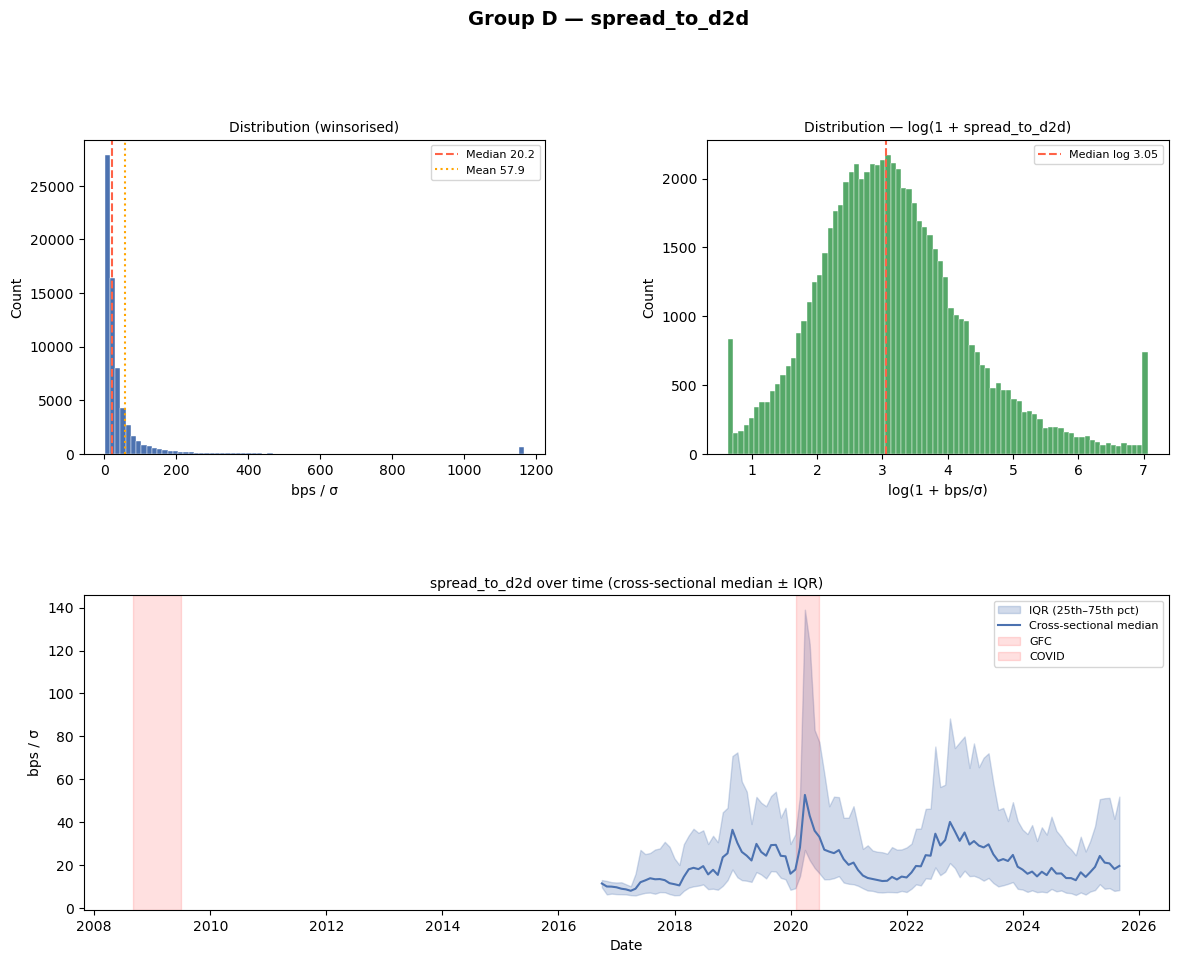

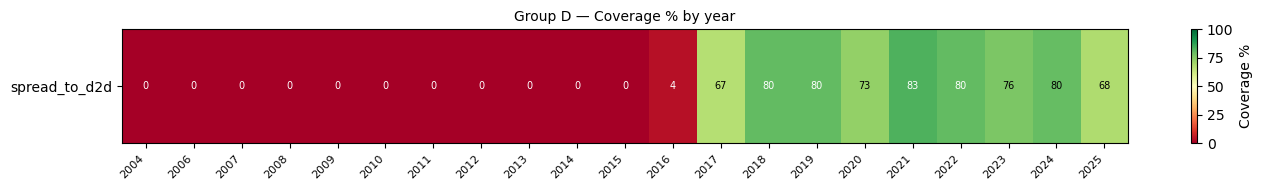

In [6]:
# ── Group D: Dependent Characteristics Overview ──────────────────────────────
# Characteristic #26: spread_to_d2d = OAS / Distance-to-Default
# A bond "value" factor: high value = high spread per unit of credit risk
# Reference: Correia et al. (2012), KPP (2021) Table IX
# NOTE: #29 vix_beta excluded pending VIX data availability
# ─────────────────────────────────────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

out_dir = Path("outputs")

# ── Load ──────────────────────────────────────────────────────────────────────
out = pd.read_parquet(out_dir / "characteristics_group_d.parquet").reset_index()
out["month_end"] = pd.to_datetime(out["month_end"])
out["year"] = out["month_end"].dt.year

char_cols = ["spread_to_d2d"]

# ── Text summary ──────────────────────────────────────────────────────────────
print("=" * 60)
print("GROUP D — DEPENDENT CHARACTERISTICS")
print("=" * 60)
print(f"Shape          : {out.shape[0]:,} rows × {len(char_cols)} characteristic")
print(f"Unique RICs    : {out['RIC'].nunique():,}")
print(f"Date range     : {out['month_end'].min().date()} → {out['month_end'].max().date()}")
print(f"Unique months  : {out['month_end'].nunique()}")
print()

print("--- NaN summary ---")
for col in char_cols:
    n_nan = out[col].isna().sum()
    pct   = n_nan / len(out) * 100
    print(f"  {col:<20}  NaN: {n_nan:,} ({pct:.1f}%)")
print()

print("--- Descriptive statistics ---")
print(out[char_cols].describe().round(3).to_string())
print()

# Sanity checks
n_neg   = (out["spread_to_d2d"] < 0).sum()
n_large = (out["spread_to_d2d"] > 10_000).sum()
print(f"--- Sanity checks ---")
print(f"  Negative values  : {n_neg}  (should be 0)")
print(f"  Values > 10,000  : {n_large}  (should be 0 after winsorisation)")
lo = out["spread_to_d2d"].quantile(0.01)
hi = out["spread_to_d2d"].quantile(0.99)
print(f"  Winsorise bounds : [{lo:.2f}, {hi:.2f}]  bps / σ")

# ── Figure ────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(14, 10))
fig.suptitle("Group D — spread_to_d2d", fontsize=14, fontweight="bold", y=1.01)
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)

series = out["spread_to_d2d"].dropna()

# Panel 1: Distribution histogram
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(series, bins=80, color="#4C72B0", edgecolor="white", linewidth=0.3)
ax1.axvline(series.median(), color="tomato", lw=1.5, linestyle="--", label=f"Median {series.median():.1f}")
ax1.axvline(series.mean(),   color="orange", lw=1.5, linestyle=":",  label=f"Mean {series.mean():.1f}")
ax1.set_title("Distribution (winsorised)", fontsize=10)
ax1.set_xlabel("bps / σ")
ax1.set_ylabel("Count")
ax1.legend(fontsize=8)

# Panel 2: Log-scale distribution (spread_to_d2d is right-skewed)
ax2 = fig.add_subplot(gs[0, 1])
log_series = np.log1p(series)
ax2.hist(log_series, bins=80, color="#55A868", edgecolor="white", linewidth=0.3)
ax2.axvline(log_series.median(), color="tomato", lw=1.5, linestyle="--",
            label=f"Median log {log_series.median():.2f}")
ax2.set_title("Distribution — log(1 + spread_to_d2d)", fontsize=10)
ax2.set_xlabel("log(1 + bps/σ)")
ax2.set_ylabel("Count")
ax2.legend(fontsize=8)

# Panel 3: Time-series of cross-sectional median + IQR
ax3 = fig.add_subplot(gs[1, :])
ts = (out.groupby("month_end")["spread_to_d2d"]
         .agg(median="median", q25=lambda x: x.quantile(0.25),
              q75=lambda x: x.quantile(0.75))
         .reset_index())

ax3.fill_between(ts["month_end"], ts["q25"], ts["q75"],
                 alpha=0.25, color="#4C72B0", label="IQR (25th–75th pct)")
ax3.plot(ts["month_end"], ts["median"], color="#4C72B0", lw=1.5, label="Cross-sectional median")
ax3.set_title("spread_to_d2d over time (cross-sectional median ± IQR)", fontsize=10)
ax3.set_xlabel("Date")
ax3.set_ylabel("bps / σ")
ax3.legend(fontsize=8)

# Shade known stress periods
stress = [("2008-09-01", "2009-06-30", "GFC"),
          ("2020-02-01", "2020-06-30", "COVID")]
for start, end, label in stress:
    ax3.axvspan(pd.Timestamp(start), pd.Timestamp(end),
                alpha=0.12, color="red", label=label)

# Deduplicate legend entries
handles, labels = ax3.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax3.legend(by_label.values(), by_label.keys(), fontsize=8)

plt.tight_layout()
plt.show()

# ── Annual coverage heatmap ───────────────────────────────────────────────────
fig2, ax_h = plt.subplots(figsize=(14, 2))
cov = (out.groupby("year")["spread_to_d2d"]
          .apply(lambda x: x.notna().mean() * 100)
          .to_frame().T)

im = ax_h.imshow(cov.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
plt.colorbar(im, ax=ax_h, label="Coverage %")
ax_h.set_xticks(range(len(cov.columns)))
ax_h.set_xticklabels(cov.columns, rotation=45, ha="right", fontsize=8)
ax_h.set_yticks([0])
ax_h.set_yticklabels(["spread_to_d2d"])
for j, val in enumerate(cov.values[0]):
    ax_h.text(j, 0, f"{val:.0f}", ha="center", va="center",
              fontsize=7, color="black" if 20 < val < 80 else "white")
ax_h.set_title("Group D — Coverage % by year", fontsize=10)
plt.tight_layout()
plt.show()

CHARACTERISTICS_ALL — FINAL PANEL SUMMARY
Shape          : 97,893 rows × 28 characteristics (+ constant)
Unique RICs    : 1,699
Date range     : 2004-07-31 → 2025-09-30
Unique months  : 201

  Group A — Static bond: ['bond_age', 'coupon', 'face_value', 'duration', 'spread', 'rating']
  Group B — Rolling bond: ['mom_6m', 'mom_6m_industry', 'mom_6m_x_rating', 'bond_skewness', 'mom_6m_log_spread', 'bond_volatility', 'value_at_risk']
  Group C — Firm-level: ['book_to_price', 'debt_to_ebitda', 'mom_6m_equity', 'earnings_to_price', 'equity_market_cap', 'equity_volatility', 'firm_total_debt', 'book_leverage', 'market_leverage', 'turnover_volatility', 'operating_leverage', 'profitability', 'profitability_change', 'distance_to_default']
  Group D — Dependent: ['spread_to_d2d']

--- NaN % per characteristic ---
  [A] bond_age                     0.0%
  [A] coupon                       0.0%
  [A] face_value                   0.0%
  [A] duration                     0.0%
  [A] spread               

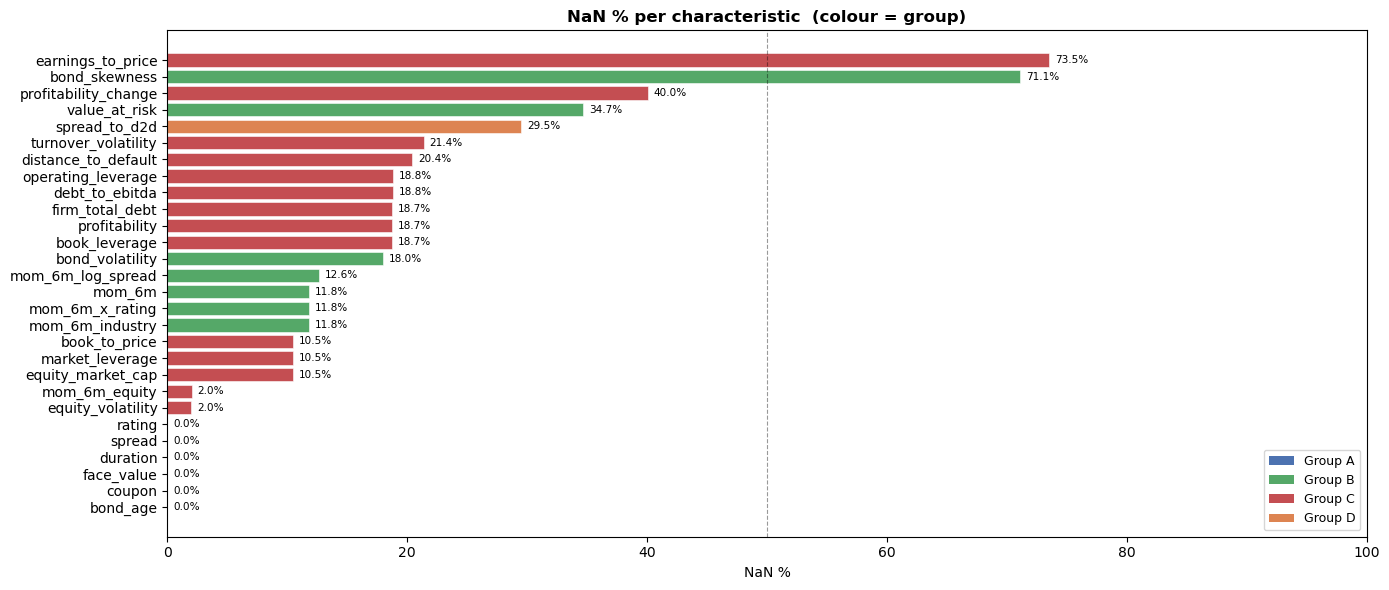

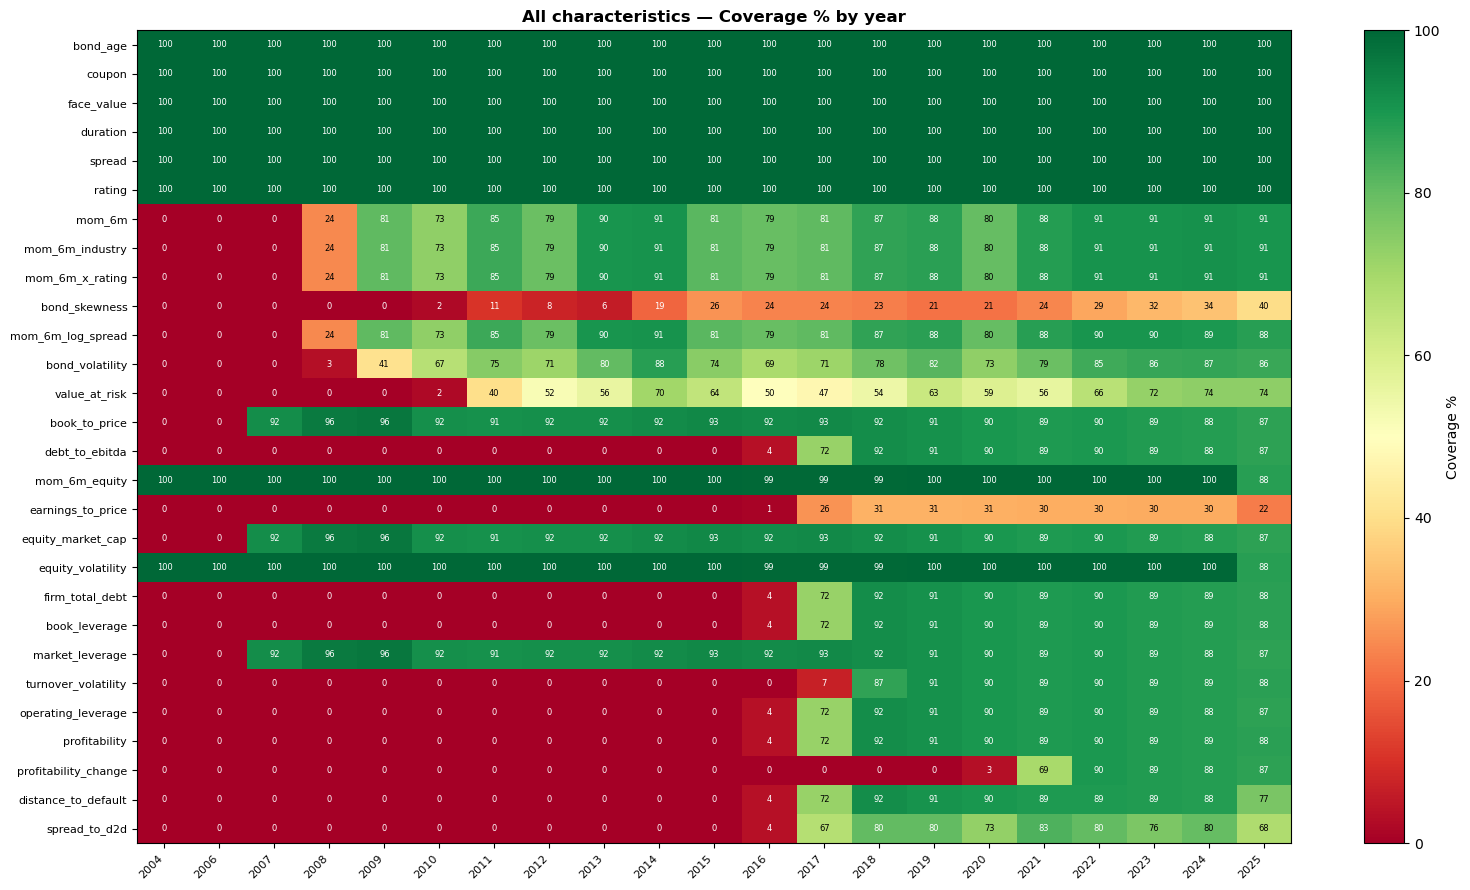

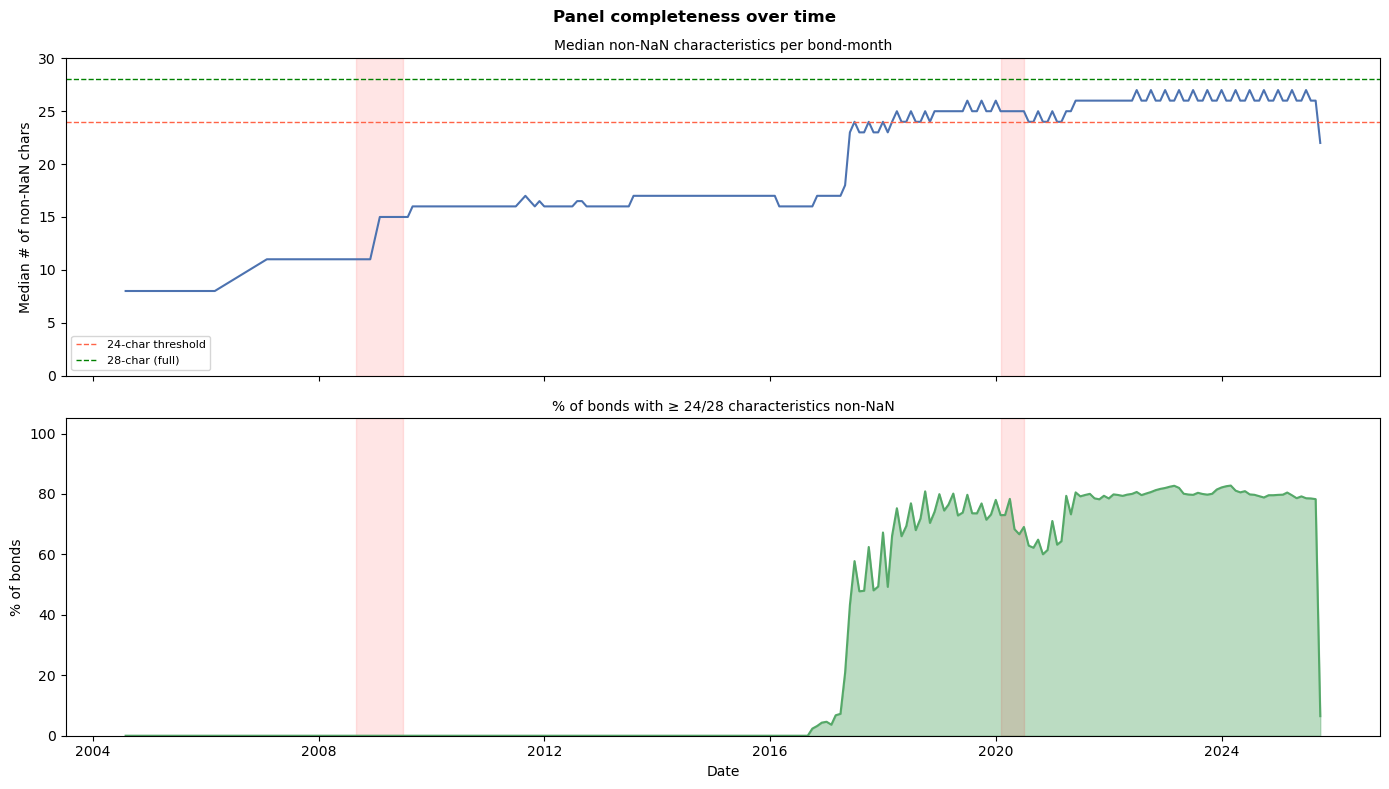

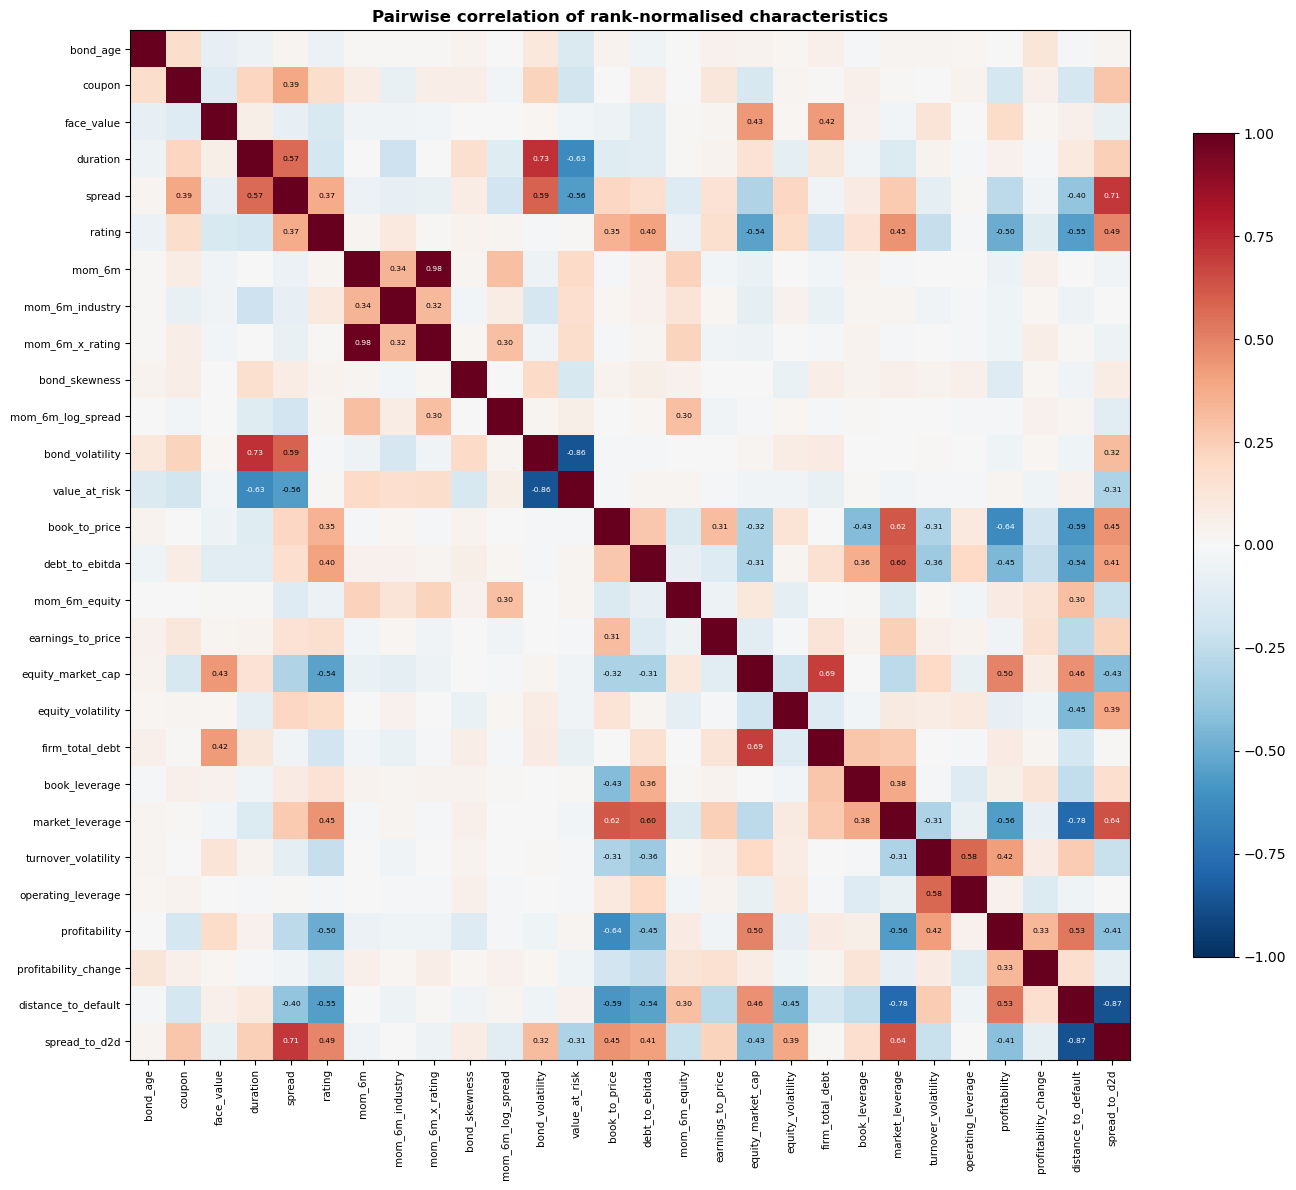

In [7]:
# ── characteristics_all: Final Panel Overview ────────────────────────────────
# Summary of the complete 28-characteristic instrument panel (excl. vix_beta)
# used as the IPCA instrument vector z_{i,t}.
# ─────────────────────────────────────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

out_dir = Path("outputs")

# ── Load ──────────────────────────────────────────────────────────────────────
out = pd.read_parquet(out_dir / "characteristics_all.parquet").reset_index()
out["month_end"] = pd.to_datetime(out["month_end"])
out["year"] = out["month_end"].dt.year

CHAR_COLS = [c for c in out.columns if c not in ("RIC", "month_end", "year", "constant")]

# Group labels for colour-coding
GROUP = {
    "bond_age": "A", "coupon": "A", "face_value": "A",
    "duration": "A", "spread": "A", "rating": "A",
    "mom_6m": "B", "mom_6m_industry": "B", "mom_6m_x_rating": "B",
    "bond_skewness": "B", "mom_6m_log_spread": "B",
    "bond_volatility": "B", "value_at_risk": "B",
    "book_to_price": "C", "debt_to_ebitda": "C", "mom_6m_equity": "C",
    "earnings_to_price": "C", "equity_market_cap": "C",
    "equity_volatility": "C", "firm_total_debt": "C",
    "book_leverage": "C", "market_leverage": "C",
    "turnover_volatility": "C", "operating_leverage": "C",
    "profitability": "C", "profitability_change": "C",
    "distance_to_default": "C", "spread_to_d2d": "D",
}
GROUP_COLORS = {"A": "#4C72B0", "B": "#55A868", "C": "#C44E52", "D": "#DD8452"}

# ── Text summary ──────────────────────────────────────────────────────────────
print("=" * 65)
print("CHARACTERISTICS_ALL — FINAL PANEL SUMMARY")
print("=" * 65)
print(f"Shape          : {out.shape[0]:,} rows × {len(CHAR_COLS)} characteristics (+ constant)")
print(f"Unique RICs    : {out['RIC'].nunique():,}")
print(f"Date range     : {out['month_end'].min().date()} → {out['month_end'].max().date()}")
print(f"Unique months  : {out['month_end'].nunique()}")
print()

for grp_name, grp_label in [("A — Static bond", "A"), ("B — Rolling bond", "B"),
                              ("C — Firm-level", "C"),  ("D — Dependent", "D")]:
    cols = [c for c in CHAR_COLS if GROUP.get(c) == grp_label]
    print(f"  Group {grp_name}: {cols}")
print()

print("--- NaN % per characteristic ---")
nan_pct = out[CHAR_COLS].isna().mean().mul(100).sort_values()
for col, pct in nan_pct.items():
    grp   = GROUP.get(col, "?")
    flag  = " ⚠" if pct > 50 else ""
    print(f"  [{grp}] {col:<25}  {pct:5.1f}%{flag}")
print()

# How many bond-months have at least N chars non-NaN
print("--- Usable observations by completeness threshold ---")
n_present = out[CHAR_COLS].notna().sum(axis=1)
for threshold in [20, 24, 26, 28]:
    n = (n_present >= threshold).sum()
    pct = n / len(out) * 100
    print(f"  ≥ {threshold}/28 chars non-NaN : {n:,} rows  ({pct:.1f}%)")

# ── Figure 1: NaN % bar chart by characteristic ───────────────────────────────
fig1, ax = plt.subplots(figsize=(14, 6))
colors = [GROUP_COLORS[GROUP.get(c, "A")] for c in nan_pct.index]
bars = ax.barh(nan_pct.index, nan_pct.values, color=colors, edgecolor="white", linewidth=0.4)
ax.axvline(50, color="black", lw=0.8, linestyle="--", alpha=0.4, label="50% threshold")
ax.set_xlabel("NaN %")
ax.set_title("NaN % per characteristic  (colour = group)", fontsize=12, fontweight="bold")
ax.set_xlim(0, 100)
for bar, val in zip(bars, nan_pct.values):
    ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%", va="center", fontsize=7.5)
# Legend for groups
from matplotlib.patches import Patch
legend_els = [Patch(facecolor=v, label=f"Group {k}") for k, v in GROUP_COLORS.items()]
ax.legend(handles=legend_els, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

# ── Figure 2: Coverage heatmap (all chars × year) ─────────────────────────────
coverage = (
    out.groupby("year")[CHAR_COLS]
       .apply(lambda x: x.notna().mean() * 100)
       .T
)

fig2, ax2 = plt.subplots(figsize=(16, 9))
im = ax2.imshow(coverage.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
plt.colorbar(im, ax=ax2, label="Coverage %")
ax2.set_xticks(range(len(coverage.columns)))
ax2.set_xticklabels(coverage.columns, rotation=45, ha="right", fontsize=8)
ax2.set_yticks(range(len(coverage.index)))
ax2.set_yticklabels(coverage.index, fontsize=8)
ax2.set_title("All characteristics — Coverage % by year", fontsize=12, fontweight="bold")
for i in range(len(coverage.index)):
    for j in range(len(coverage.columns)):
        val = coverage.values[i, j]
        ax2.text(j, i, f"{val:.0f}", ha="center", va="center",
                 fontsize=6, color="black" if 20 < val < 80 else "white")
plt.tight_layout()
plt.show()

# ── Figure 3: Cross-sectional completeness over time ──────────────────────────
# For each month: median number of non-NaN chars across bonds
monthly_complete = (
    out.groupby("month_end")[CHAR_COLS]
       .apply(lambda x: x.notna().sum(axis=1).median())
       .reset_index(name="median_n_chars")
)
monthly_frac = (
    out.groupby("month_end")[CHAR_COLS]
       .apply(lambda x: (x.notna().sum(axis=1) >= 24).mean() * 100)
       .reset_index(name="pct_ge24")
)

fig3, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig3.suptitle("Panel completeness over time", fontsize=12, fontweight="bold")

axes[0].plot(monthly_complete["month_end"], monthly_complete["median_n_chars"],
             color="#4C72B0", lw=1.5)
axes[0].axhline(24, color="tomato", lw=1, linestyle="--", label="24-char threshold")
axes[0].axhline(28, color="green",  lw=1, linestyle="--", label="28-char (full)")
axes[0].set_ylabel("Median # of non-NaN chars")
axes[0].set_ylim(0, 30)
axes[0].legend(fontsize=8)
axes[0].set_title("Median non-NaN characteristics per bond-month", fontsize=10)

axes[1].fill_between(monthly_frac["month_end"], monthly_frac["pct_ge24"],
                     alpha=0.4, color="#55A868")
axes[1].plot(monthly_frac["month_end"], monthly_frac["pct_ge24"],
             color="#55A868", lw=1.5)
axes[1].set_ylabel("% of bonds")
axes[1].set_ylim(0, 105)
axes[1].set_title("% of bonds with ≥ 24/28 characteristics non-NaN", fontsize=10)
axes[1].set_xlabel("Date")

for ax in axes:
    for start, end, label in [("2008-09-01", "2009-06-30", "GFC"),
                               ("2020-02-01", "2020-06-30", "COVID")]:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end),
                   alpha=0.1, color="red")

plt.tight_layout()
plt.show()

# ── Figure 4: Pairwise correlation heatmap (rank-normalised) ──────────────────
# Rank-normalise each characteristic cross-sectionally before correlating
# (mirrors IPCA pre-processing)
ranked = out[CHAR_COLS].rank(pct=True) - 0.5   # centre at 0

corr = ranked.corr()

fig4, ax4 = plt.subplots(figsize=(14, 12))
im4 = ax4.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(im4, ax=ax4, shrink=0.8)
ax4.set_xticks(range(len(CHAR_COLS)))
ax4.set_xticklabels(CHAR_COLS, rotation=90, fontsize=7.5)
ax4.set_yticks(range(len(CHAR_COLS)))
ax4.set_yticklabels(CHAR_COLS, fontsize=7.5)
ax4.set_title("Pairwise correlation of rank-normalised characteristics",
              fontsize=12, fontweight="bold")
# Annotate cells with |corr| > 0.3
for i in range(len(CHAR_COLS)):
    for j in range(len(CHAR_COLS)):
        val = corr.values[i, j]
        if abs(val) > 0.3 and i != j:
            ax4.text(j, i, f"{val:.2f}", ha="center", va="center",
                     fontsize=5.5, color="white" if abs(val) > 0.6 else "black")
plt.tight_layout()
plt.show()